# Natural movement: the cross-spectrum phase method on field data
Field-data counterpart of `Synthetic_Movement.ipynb`, with the same figures. Two borehole-radar profiles from the injection experiment (Chapter 7, `TimeLapse_Notebooks/fielddata`) are processed as in `FieldData_Final_Pipeline.ipynb`, but only for the chosen pair:
1. load the baseline and monitor profiles and the pre-injection reference (profile 0), and condition them: bandpass, DC removal, alignment to the reference, SVD suppression, linear gain;
2. Kirchhoff-BP migration (delta wavelet, as in Chapter 7) minus the migrated reference, then the amplitude gate;
3. cross-spectrum phase WLS in an analysis window around the target.

The last section repeats this for every consecutive pair and accumulates the shifts, to track the movement through the injection stages.

Run with the `gprMax` kernel. The `gdp` processing package is imported from its source folder, so the `gdp` environment (whose matplotlib cannot render text) is not needed. One pair takes about 15 s; the movement-over-time section takes about 1.5 min.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import gaussian_filter
from scipy.signal import hilbert

# Repository root = the folder holding TimeLapse_Notebooks/ (works from New_Figures/ or the root)
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / 'TimeLapse_Notebooks').is_dir())
GDP_SRC = Path(r'C:\Users\Administrator\GPR_Processing\georadar-data-processing')  # gdp source
sys.path[:0] = [str(REPO_ROOT / 'TimeLapse_Notebooks'), str(GDP_SRC)]
from gdp.data_io import load_mala
from gdp.preprocessing.filtering import filter_data, remove_mean
from gdp.preprocessing.gain import linear_gain
from gdp.preprocessing.image_processing import remove_svd
from gdp.preprocessing.trace_ops import align_traces
from helper_functions.KirchhoffPylopsZeroOffset import Kirchhoff
from helper_functions.migration import wls_phase_plane_fit

DATA = REPO_ROOT / 'TimeLapse_Notebooks' / 'fielddata' / 'raw_data' / '060616'   # MALA profiles
OUT_DIR = REPO_ROOT / 'New_Figures' / 'figures'                                  # saved figures
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Same figure style as Synthetic_Movement.ipynb
FIG_SCALE = 1.4        # enlarges the figures; fonts, lines and markers scale with it
sns.set_theme(style='ticks', context='paper', font_scale=FIG_SCALE,
              rc={'lines.linewidth': FIG_SCALE, 'image.interpolation': 'nearest'})


def edge_extent(ax_h, ax_v):
    """imshow extent whose pixel edges (not centres) bracket the sample axes."""
    hh, hv = 0.5 * (ax_h[1] - ax_h[0]), 0.5 * (ax_v[1] - ax_v[0])
    return [ax_h[0] - hh, ax_h[-1] + hh, ax_v[0] - hv, ax_v[-1] + hv]

## Parameters
Choose the baseline (`RUN_A`) and monitor (`RUN_B`) profile: 1–38, there is no profile 6. A scan over all consecutive pairs (this notebook's processing and default window, ranked by the strength of the fitted phase ramp relative to the fit residual) gave the cleanest phase spectra for **2 → 3** and **1 → 2** (the Letter's field pair), followed by 8 → 9, 3 → 4 and 5 → 7. Pairs with a small residual but almost no movement (e.g. 15 → 16) have a flat, uninformative phase.

The analysis window should contain the change. For the early pairs it lies at about 70–79 m depth and 4–7.5 m from the borehole. Check the difference panel of the migrated-image figure when you change the pair.

In [2]:
RUN_A, RUN_B = 1, 3          # baseline and monitor profile (0 = pre-injection reference)

# Survey and imaging constants (Chapter 7, FieldData_Final_Pipeline.ipynb)
V_PROP = 0.10                # propagation velocity [m/ns]
F0 = 0.10                    # centre frequency [GHz]
LAM = V_PROP / F0            # nominal wavelength [m]
K_C = 2 * np.pi / LAM        # central wavenumber [rad/m]
DL = 0.05                    # trace spacing along the borehole [m]
MAX_DEPTH = 85.0             # depth of the first trace [m]
RAD_CUT = 300                # time samples kept for imaging
X_INJ, Z_INJ = 6.0, 79.0     # tracer injection point: radial distance [m], depth [m]

# Cross-spectrum phase WLS
ROI_DEPTH = (68.0, 79.0)     # analysis window: depth range [m]
ROI_RADIAL = (4.0, 7.5)      # analysis window: radial distance from the borehole [m]
AMP_THR = 0.30               # fit the bins with |XS| > AMP_THR * max|XS|
WLS_POW = 3                  # WLS weights |XS|**WLS_POW, as in the thesis' field fits
PAD_FAC = 16                 # FFT zero-padding: finer k sampling (more pixels), same estimate

RUNS = list(range(1, 6)) + list(range(7, 39))
assert RUN_A in RUNS and RUN_B in RUNS, f'profiles must be in {RUNS}'

## Loading and conditioning
The five-step conditioning chain of `FieldData_Final_Pipeline.ipynb` (cell 8). The reference is aligned to itself and every profile to the aligned reference, so conditioning only the reference and the two chosen profiles gives exactly the pipeline's arrays for this pair. B-scans are traces-first, `(n_traces, RAD_CUT)`.

The last lines measure the dominant wavelength $\lambda$: the peak of the conditioned reference profile's mean amplitude spectrum, about 69 MHz, so $\lambda \approx 1.44$ m at 0.10 m/ns (the nominal 100 MHz would give 1 m). The reference is measured, so $\lambda$ is the same for every pair; the other profiles and the target zone agree within 3 %. $\lambda$ is the length unit of panel (a) of the cross-spectrum figure.

In [3]:
def load_profile(run):
    """Raw MALA profile (run 0 = prof, the pre-injection reference) and its header."""
    return load_mala(str(DATA / ('prof' if run == 0 else f'prof{run}')), return_object=False)


ref_raw, header = load_profile(0)
SF = header['frequency (GHz)']                           # sampling frequency [GHz]
N_SAMPLES, N_TRACES = ref_raw.shape
T_AXIS = np.arange(1, N_SAMPLES + 1) / SF                # two-way time [ns]
DEPTH_AXIS = np.linspace(MAX_DEPTH, MAX_DEPTH - N_TRACES * DL, N_TRACES)   # trace depths [m]


def condition(raw, align_to, *, align_reference=False, normalize_align=True):
    """Bandpass, DC removal, alignment, SVD suppression and linear gain (pipeline cell 8)."""
    n = min(raw.shape[1], N_TRACES)
    x = filter_data(raw[:, :n], fq=(0.02, 0.20), sfreq=SF, btype='bandpass')
    x, _ = remove_mean(x, 299, 517)
    x, _, _ = align_traces(x, align_to[:, :n], upsample=5, normalize=normalize_align,
                           align_reference=align_reference)
    x, _ = remove_svd(x, low_s=0, high_s=1)
    x, _ = linear_gain(x, T_AXIS)
    return x[:RAD_CUT, :].T


_ref_dc, _ = remove_mean(filter_data(ref_raw, fq=(0.02, 0.20), sfreq=SF, btype='bandpass'), 299, 517)
ref_aligned, _, _ = align_traces(_ref_dc, _ref_dc, upsample=5, normalize=False, align_reference=True)
BSCAN = {'reference': condition(ref_raw, ref_aligned, align_reference=True, normalize_align=False),
         'baseline': condition(load_profile(RUN_A)[0], ref_aligned),
         'monitor': condition(load_profile(RUN_B)[0], ref_aligned)}

# Dominant wavelength: peak of the mean amplitude spectrum of the conditioned reference profile
spec = np.abs(np.fft.rfft(BSCAN['reference'] * np.hanning(RAD_CUT), n=16 * RAD_CUT, axis=1)).mean(axis=0)
F_DOM = np.fft.rfftfreq(16 * RAD_CUT, d=1 / SF)[np.argmax(spec)]   # dominant frequency [GHz]
LAM_DOM = V_PROP / F_DOM                                            # dominant wavelength [m]
print({name: b.shape for name, b in BSCAN.items()}, f'sampling {SF:.3f} GHz\n'
      f'dominant frequency {F_DOM * 1e3:.0f} MHz, wavelength {LAM_DOM:.2f} m (nominal {LAM:.2f} m)')

{'reference': (461, 300), 'baseline': (461, 300), 'monitor': (461, 300)} sampling 1.148 GHz
dominant frequency 69 MHz, wavelength 1.44 m (nominal 1.00 m)


## Kirchhoff-BP migration
The thesis' zero-offset Kirchhoff operator with the antennas in the borehole (radial distance 0, at the trace depths) and a delta wavelet: the "Kirchhoff-BP" variant of Chapter 7. The image grid is the pipeline's (radial axis `X_IMG` from the time samples, depth axis from the traces), with depth increasing downwards along the rows. Each profile's migration minus the migrated reference then goes through the pipeline's amplitude gate: the image is weighted by its smoothed envelope relative to the envelope's 80th percentile, capped at 1.

In [4]:
T_MIG = T_AXIS[:RAD_CUT]
X_IMG = np.linspace(0, V_PROP * T_MIG[-1] / 2, RAD_CUT)  # radial distance from the borehole [m]
Z_IMG = DEPTH_AXIS[::-1].copy()                          # depth [m], increasing with row
DX_IMG, DZ_IMG = X_IMG[1] - X_IMG[0], Z_IMG[1] - Z_IMG[0]

def kirchhoff_images(bscans):
    """Kirchhoff-BP images (n_depth, n_radial) of a dict of B-scans, all through one operator
    (every profile is cropped to N_TRACES traces); the operator is freed on return."""
    recs = np.vstack((np.zeros(N_TRACES), DEPTH_AXIS))  # antenna positions (radial 0, depth)
    K = Kirchhoff(Z_IMG, X_IMG, T_MIG, recs, recs, V_PROP, np.ones(1), 0)   # delta wavelet
    return {name: (K.H @ b.ravel()).reshape(len(X_IMG), len(Z_IMG)).T for name, b in bscans.items()}


def amplitude_gate(img, sigma_m=0.15, percentile=80):
    """Pipeline post-imaging (apply_post_imaging, Kirchhoff-BP): local-envelope amplitude gate."""
    env = gaussian_filter(np.abs(img), (sigma_m / DZ_IMG, sigma_m / DX_IMG))
    return img * np.clip(env / np.percentile(env, percentile), 0, 1)


MIG = kirchhoff_images(BSCAN)
IMG = {name: amplitude_gate(MIG[name] - MIG['reference']) for name in ('baseline', 'monitor')}

## Cross-spectrum phase WLS
As in `Synthetic_Movement.ipynb`: Tukey-tapered window, cross-spectrum $XS = \mathrm{FFT2}(b)\cdot\mathrm{FFT2}(m)^*$ (zero-padded), and a WLS phase-plane fit over both lobes above the energy threshold. There are two differences:
- **The intercept flips sign between the lobes.** In this borehole geometry the waves travel radially, so the carrier axis is $x$ and the lobes sit at $\pm k_x$. Field data carry a phase offset $\phi_0 \neq 0$, because the reflection itself changes, not just its position. Since $XS(-\mathbf{k}) = XS(\mathbf{k})^*$, the mirror lobe has the opposite phase, so the plane is $\arg XS = k_z\Delta z + k_x\Delta x + \mathrm{sign}(k_x)\,\phi_0$. One shared plane through both lobes, as in the synthetic notebook (where $\phi_0 \approx 0$), would force $\phi_0 = 0$ and leak the offset into $\Delta x$. The sign-flipping fit gives exactly the result of fitting the $k_x > 0$ lobe alone, as the thesis' field processing does; the single-plane result is printed for comparison.
- **Weights $|XS|^3$** (`WLS_POW`), as in the thesis' field fits, suppress the low-energy fringe of the lobes.

`cross_spectrum_fit` also returns a **quality** number: the weighted spread of the fitted plane over the lobes divided by the weighted phase residual. Below about 1 the phase in the lobes is mostly noise, which happens when the profiles barely changed.

There are no true positions to mark in field data. The markers use the point of largest change instead: the peak of the difference envelope (along the radial carrier axis) in the window (○), and that point shifted by the WLS estimate (×). The estimate itself is a weighted average over the whole reflector in the window. For a near-vertical reflector that moves along its own length, the difference lights up mostly at its ends, which is where the markers sit. Positive $\Delta x$ is away from the borehole and positive $\Delta z$ is deeper.

In [5]:
XS_KW = dict(taper='tukey', tukey_alpha=0.15, pad_fac=PAD_FAC)


def cross_spectrum_fit(base, mon):
    """Zero-padded cross-spectrum of two windowed images and the WLS fit of
    arg XS = kz dz + kx dx + sign(kx) phi0 over both lobes above the energy threshold (the
    Hermitian mirror lobe carries -phi0). 'quality' = |XS|^WLS_POW-weighted spread of the fitted
    plane over the lobes divided by the weighted phase residual: below ~1 the phase is mostly noise."""
    diag = wls_phase_plane_fit(base, mon, DZ_IMG, DX_IMG, K_C, return_diagnostics=True, **XS_KW)[4]
    mask = (diag['w'] > AMP_THR * diag['w'].max()) & (diag['KX'] != 0)
    W = diag['w'][mask] ** WLS_POW
    A = np.column_stack([diag['KZ'][mask], diag['KX'][mask], np.sign(diag['KX'][mask])])
    dz, dx, phi0 = np.linalg.lstsq(A * W[:, None], diag['phi'][mask] * W, rcond=None)[0]
    plane = A @ (dz, dx, phi0)
    residual = np.angle(np.exp(1j * (diag['phi'][mask] - plane)))
    spread = np.sqrt(np.average((plane - np.average(plane, weights=W)) ** 2, weights=W))
    quality = spread / np.sqrt(np.average(residual ** 2, weights=W))
    return dict(dz=dz, dx=dx, phi0=phi0, quality=quality, mask=mask, diag=diag)


iz = (Z_IMG >= ROI_DEPTH[0]) & (Z_IMG <= ROI_DEPTH[1])
ix = (X_IMG >= ROI_RADIAL[0]) & (X_IMG <= ROI_RADIAL[1])
z_roi, x_roi = Z_IMG[iz], X_IMG[ix]
base, mon = IMG['baseline'][np.ix_(iz, ix)], IMG['monitor'][np.ix_(iz, ix)]

fit = cross_spectrum_fit(base, mon)
dz_est, dx_est, phi0, fit_mask, diag = (fit[k] for k in ('dz', 'dx', 'phi0', 'mask', 'diag'))
XS, kz_ax, kx_ax = diag['w'] * np.exp(1j * diag['phi']), diag['kz_ax'], diag['kx_ax']
n_fit = int(fit_mask.sum())

# For comparison: one shared plane through both lobes (the synthetic notebook's model)
dz_1p, dx_1p, _, _ = wls_phase_plane_fit(base, mon, DZ_IMG, DX_IMG, K_C, mask=fit_mask,
                                         wls_pow=WLS_POW, **XS_KW)

# Marker positions: the point of largest change (difference-envelope peak in the window) and the
# same point shifted by the estimate
env = np.abs(hilbert(mon - base, axis=1))
i0, j0 = np.unravel_index(np.argmax(env), env.shape)
POS = {'baseline': (x_roi[j0], z_roi[i0]),
       'monitor': (x_roi[j0] + dx_est, z_roi[i0] + dz_est)}

print(f'profiles {RUN_A} -> {RUN_B}: dx = {dx_est:+.3f} m (+ = away from the borehole), '
      f'dz = {dz_est:+.3f} m (+ = deeper), phi0 = {phi0:+.2f} rad, {n_fit} fitted bins, '
      f'quality {fit["quality"]:.1f}\n'
      f'one shared plane (forces phi0 = 0): dx = {dx_1p:+.3f} m, dz = {dz_1p:+.3f} m')

profiles 1 -> 3: dx = -0.238 m (+ = away from the borehole), dz = -1.774 m (+ = deeper), phi0 = -0.59 rad, 2014 fitted bins, quality 7.0
one shared plane (forces phi0 = 0): dx = -0.311 m, dz = -1.729 m


## Figures
### Migrated images
The migrated baseline and monitor profiles and their difference, as in `Synthetic_Movement.ipynb`. The colour scale of each panel is set by the analysis window, so the target is not swamped by stronger energy elsewhere. The dashed green box is the analysis window. The markers show the point of largest change (○) and that point shifted by the WLS estimate (×), and the inset zooms on them. The star (★) is the tracer injection point, 6 m from the borehole at 79 m depth.

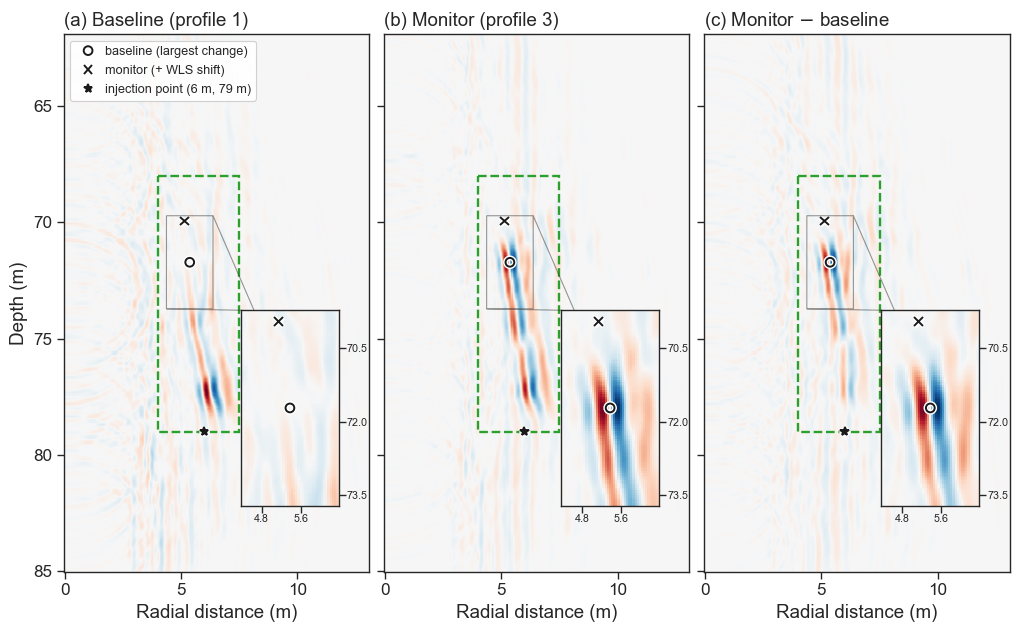

In [6]:
ZOOM_HW = (1.0, 2.0)          # half-width of the zoom inset around the baseline marker (radial, depth) [m]
MK = dict(ms=4.5 * FIG_SCALE, mew=FIG_SCALE, ls='none',      # white halo: visible on any colour
          path_effects=[pe.withStroke(linewidth=2.5 * FIG_SCALE, foreground='w')])
MARKER_LABELS = ('baseline (largest change)', 'monitor (+ WLS shift)',
                 f'injection point ({X_INJ:g} m, {Z_INJ:g} m)')


def plot_markers(ax, xy=lambda x, z: (x, z)):
    """Baseline and monitor markers and the injection point; `xy` maps (radial, depth) [m] to
    the panel's axes."""
    ax.plot(*xy(*POS['baseline']), marker='o', mfc='none', mec='k', label=MARKER_LABELS[0], **MK)
    ax.plot(*xy(*POS['monitor']), marker='x', mec='k', label=MARKER_LABELS[1], **MK)
    ax.plot(*xy(X_INJ, Z_INJ), marker='*', color='k', label=MARKER_LABELS[2], **MK)


def roi_box(ax, xy=lambda x, z: (x, z)):
    """The analysis window (dashed green); `xy` as in plot_markers."""
    (x0, z0), (x1, z1) = xy(ROI_RADIAL[0], ROI_DEPTH[0]), xy(ROI_RADIAL[1], ROI_DEPTH[1])
    ax.add_patch(plt.Rectangle((x0, z0), x1 - x0, z1 - z0, fill=False, ec='tab:green', ls='--',
                               lw=1.2 * FIG_SCALE))


def section_panel(ax, img, title):
    """Migrated section (depth down, equal axes, colour scale from the analysis window) with the
    analysis window, the markers and a zoom inset in the empty lower right of the panel."""
    vmax = np.abs(img[np.ix_(iz, ix)]).max()
    ext = edge_extent(X_IMG, Z_IMG)
    axin = ax.inset_axes([0.58, 0.08, 0.32, 0.45])
    for a in (ax, axin):
        a.imshow(img, extent=[ext[0], ext[1], ext[3], ext[2]], origin='upper', cmap='RdBu_r',
                 vmin=-vmax, vmax=vmax)
        plot_markers(a)
    roi_box(ax)
    x_c, z_c = POS['baseline']
    axin.set_xlim(x_c - ZOOM_HW[0], x_c + ZOOM_HW[0])
    axin.set_ylim(z_c + ZOOM_HW[1], z_c - ZOOM_HW[1])
    axin.tick_params(labelsize=5.5 * FIG_SCALE, pad=1)
    axin.yaxis.tick_right()                              # keep the labels off the window
    for axis in (axin.xaxis, axin.yaxis):
        axis.set_major_locator(plt.MaxNLocator(3))
    ax.indicate_inset_zoom(axin, edgecolor='0.2')
    ax.set_title(title, loc='left')
    ax.set_xlabel('Radial distance (m)')


fig, axs = plt.subplots(1, 3, figsize=(7.2 * FIG_SCALE, 4.6 * FIG_SCALE), sharey=True,
                        layout='constrained')
section_panel(axs[0], IMG['baseline'], f'(a) Baseline (profile {RUN_A})')
section_panel(axs[1], IMG['monitor'], f'(b) Monitor (profile {RUN_B})')
section_panel(axs[2], IMG['monitor'] - IMG['baseline'], '(c) Monitor $-$ baseline')
axs[0].set_ylabel('Depth (m)')
axs[0].legend(loc='upper left', fontsize=6.5 * FIG_SCALE, handletextpad=0.3, borderpad=0.4,
              framealpha=0.9)
fig.savefig(OUT_DIR / f'natural_movement_migrated_{RUN_A}_{RUN_B}.png', dpi=300,
            bbox_inches='tight')
plt.show()

### Cross-spectrum phase
As the final figure of `Synthetic_Movement.ipynb`:
- **(a)** The difference image (monitor $-$ baseline, relative to max|baseline| in the window), on a square view around the analysis window (dashed green), with the markers and the WLS estimate. As in the synthetic figure, the axes are displacements in wavelengths: here measured from the tracer injection point (★, 6 m from the borehole at 79 m depth), with $\lambda$ the measured dominant wavelength (about 1.44 m).
- **(b)** $\arg(XS)$, with $k$ normalised by $k_c = 2\pi f_0/v$. The two fitted lobes (at $\pm k_x$) are opaque and outlined. The marginal strips show the raw phase of the fitted bins against $k_x$ (top) and $k_z$ (right), giving two blobs per strip, as in the synthetic figure. The blue lines are the fitted plane, evaluated at each lobe's $|XS|$-weighted mean $k_z$ (top) or $k_x$ (right), with that lobe's intercept $\pm\phi_0$. Both lines in a strip share the slope $\Delta x$ (top) or $\Delta z$ (right).

Saved to `New_Figures/figures/natural_movement_cross_spectrum_<RUN_A>_<RUN_B>.png` (dpi = 300).

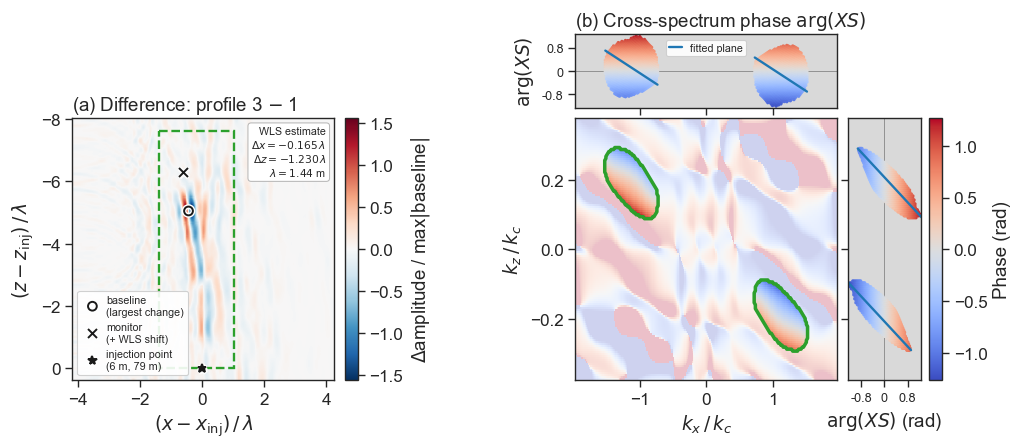

In [7]:
PHASE_CMAP = 'coolwarm'  # diverging phase map: blue (-) -> grey (0) -> red (+)
ALPHA_LOW = 0.25       # alpha outside the fitted lobes: the field phase there is incoherent, so it
                       # is faded harder than in Synthetic_Movement (as in the Letter's field figure)
MARG_FRAC = 0.28       # thickness of the marginal strips [fraction of panel (b)]
K_PAD = 1.3            # k-window: K_PAD x the fitted lobes' extent

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(7.2 * FIG_SCALE, 3.8 * FIG_SCALE),
                                 layout='constrained')
fig.get_layout_engine().set(wspace=0.14)    # room for panel (a)'s colour-bar label
fs = 6.5 * FIG_SCALE                         # small-print font size

# (a) Difference image on a square view around the analysis window, depth increasing downwards,
# on axes relative to the injection point in dominant wavelengths (as the synthetic figure)
def to_lam(x, z):
    """(radial, depth) [m] -> displacement from the injection point [dominant wavelengths]."""
    return (x - X_INJ) / LAM_DOM, (z - Z_INJ) / LAM_DOM


diff = (IMG['monitor'] - IMG['baseline']) / np.abs(base).max()
vmax = np.abs(diff[np.ix_(iz, ix)]).max()
ext = edge_extent(*to_lam(X_IMG, Z_IMG))
im_a = ax_a.imshow(diff, extent=[ext[0], ext[1], ext[3], ext[2]], origin='upper', cmap='RdBu_r',
                   vmin=-vmax, vmax=vmax)
roi_box(ax_a, to_lam)
plot_markers(ax_a, to_lam)
hw = 0.5 * max(np.ptp(ROI_RADIAL), np.ptp(ROI_DEPTH)) / LAM_DOM + 0.4   # 0.4 lambda margin
x_c, z_c = to_lam(np.mean(ROI_RADIAL), np.mean(ROI_DEPTH))
x_lo = max(x_c - hw, ext[0])                              # no blank beyond the borehole (x = 0 m)
ax_a.set_xlim(x_lo, x_lo + 2 * hw)
ax_a.set_ylim(z_c + hw, z_c - hw)
ax_a.set_xlabel(r'$(x - x_\mathrm{inj})\,/\,\lambda$')
ax_a.set_ylabel(r'$(z - z_\mathrm{inj})\,/\,\lambda$')
# Legend and estimate in the empty strips left and right of the window: two-line labels, small print
fs_a = 5.5 * FIG_SCALE
handles, labels = ax_a.get_legend_handles_labels()
ax_a.legend(handles, [lbl.replace(' (', '\n(', 1) for lbl in labels], loc='lower left',
            fontsize=fs_a, handletextpad=0.3, borderpad=0.4, framealpha=0.9)
ax_a.set_title(f'(a) Difference: profile {RUN_B} $-$ {RUN_A}', loc='left')
fig.colorbar(im_a, cax=ax_a.inset_axes([1.04, 0, 0.05, 1]),
             label=r'$\Delta$amplitude / max$|$baseline$|$')
ax_a.text(0.97, 0.97, f'WLS estimate\n$\\Delta x = {dx_est / LAM_DOM:+.3f}\\,\\lambda$\n'
          f'$\\Delta z = {dz_est / LAM_DOM:+.3f}\\,\\lambda$\n$\\lambda = {LAM_DOM:.2f}$ m',
          transform=ax_a.transAxes, fontsize=fs_a, va='top', ha='right',
          bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='0.7', lw=0.5 * FIG_SCALE))

# (b) Cross-spectrum phase (fftshifted, k / k_c), k_z increasing upwards
phase = np.fft.fftshift(np.angle(XS))
amp = np.fft.fftshift(np.abs(XS))
sel = np.fft.fftshift(fit_mask)                          # the fitted bins (both lobes)
kz_n, kx_n = np.fft.fftshift(kz_ax) / K_C, np.fft.fftshift(kx_ax) / K_C
KZ_n, KX_n = np.meshgrid(kz_n, kx_n, indexing='ij')
ph_lim = 1.05 * np.abs(phase[sel]).max()                 # colour range spans the fitted phases
im_b = ax_b.imshow(phase, extent=edge_extent(kx_n, kz_n), origin='lower', aspect='auto',
                   cmap=PHASE_CMAP, vmin=-ph_lim, vmax=ph_lim, alpha=np.where(sel, 1.0, ALPHA_LOW))
ax_b.contour(kx_n, kz_n, sel.astype(float), levels=[0.5], colors='tab:green',
             linewidths=1.8 * FIG_SCALE)
kx_lim, kz_lim = K_PAD * np.abs(KX_n[sel]).max(), K_PAD * np.abs(KZ_n[sel]).max()
ax_b.set_xlim(-kx_lim, kx_lim)
ax_b.set_ylim(-kz_lim, kz_lim)
ax_b.set_box_aspect(1)                                   # square panel
ax_b.set_xlabel(r'$k_x \,/\, k_c$')
ax_b.set_ylabel(r'$k_z \,/\, k_c$')

# Marginal strips: raw arg(XS) of the fitted bins against k_x (top) and k_z (right)
ax_top = ax_b.inset_axes([0, 1.04, 1, MARG_FRAC], sharex=ax_b)
ax_rgt = ax_b.inset_axes([1.04, 0, MARG_FRAC, 1], sharey=ax_b)
sc_kw = dict(c=phase[sel], cmap=PHASE_CMAP, vmin=-ph_lim, vmax=ph_lim, s=3 * FIG_SCALE ** 2,
             linewidths=0, rasterized=True)
ax_top.scatter(KX_n[sel], phase[sel], **sc_kw)
ax_rgt.scatter(phase[sel], KZ_n[sel], **sc_kw)

# Fitted plane phi = kx dx + kz dz + sign(kx) phi0 in the strips, one line per lobe: the plane at
# the lobe's |XS|-weighted mean k_z (top) or k_x (right), with that lobe's intercept +-phi0
fit_kw = dict(color='tab:blue', lw=1.2 * FIG_SCALE)
for s in (1, -1):                                        # k_x > 0 and k_x < 0 lobe
    m_ = sel & (np.sign(KX_n) == s)
    kz_mean, kx_mean = (np.average(k[m_], weights=amp[m_] ** WLS_POW) for k in (KZ_n, KX_n))
    kx_line = np.array([KX_n[m_].min(), KX_n[m_].max()])
    kz_line = np.array([KZ_n[m_].min(), KZ_n[m_].max()])
    ax_top.plot(kx_line, K_C * (kx_line * dx_est + kz_mean * dz_est) + s * phi0, **fit_kw)
    ax_rgt.plot(K_C * (kz_line * dz_est + kx_mean * dx_est) + s * phi0, kz_line, **fit_kw)
ax_top.legend(ax_top.lines[-1:], ['fitted plane'], loc='upper center', fontsize=5.5 * FIG_SCALE,
              handlelength=1.2, borderpad=0.3, framealpha=0.9)   # in the gap between the lobes

for ax in (ax_top, ax_rgt):
    ax.set_facecolor('0.85')
ax_top.axhline(0, color='0.5', lw=0.4 * FIG_SCALE, zorder=0)
ax_rgt.axvline(0, color='0.5', lw=0.4 * FIG_SCALE, zorder=0)
tk = float(f'{0.6 * ph_lim:.1g}')            # strip ticks well inside +-ph_lim
ticks, tick_lbls = [-tk, 0, tk], [f'{-tk:g}', '0', f'{tk:g}']
ax_top.set_ylim(-ph_lim, ph_lim)
ax_top.set_yticks(ticks, tick_lbls, fontsize=fs)
ax_top.set_ylabel(r'$\arg(XS)$')
ax_top.tick_params(labelbottom=False)
ax_rgt.set_xlim(-ph_lim, ph_lim)
ax_rgt.set_xticks(ticks, tick_lbls, fontsize=fs)
ax_rgt.set_xlabel(r'$\arg(XS)$ (rad)')
ax_rgt.tick_params(labelleft=False)
ax_top.set_title(r'(b) Cross-spectrum phase $\arg(XS)$', loc='left')
cb_b = fig.colorbar(im_b, cax=ax_b.inset_axes([1.07 + MARG_FRAC, 0, 0.05, 1]),
                    label='Phase (rad)')
cb_b.solids.set_alpha(1.0)                   # colour bar shows the opaque colours

# Align panel (a) with the phase map itself (not the map + top strip)
ax_a.set_anchor('S')
ax_b.set_anchor('S')

fig.savefig(OUT_DIR / f'natural_movement_cross_spectrum_{RUN_A}_{RUN_B}.png', dpi=300,
            bbox_inches='tight')
plt.show()

## Movement over time
The same processing and fit for every consecutive pair (1 → 2, 2 → 3, …; 5 → 7 spans the missing profile 6), with the same analysis window. Summing the per-pair shifts from profile 1 onwards gives the cumulative displacement of the reflector, which tracks the fluid front through the injection stages of Chapter 7 (Push, Chase, Wait, Pull). Each step adds its own error, so the cumulative curve drifts like a random walk where the per-pair quality is low. That is the case for most pairs in Wait and Pull, where the profiles barely change and the noise band near the borehole dominates.

All 37 profiles are conditioned and migrated (about 1.5 min). The table is saved to `New_Figures/data/natural_movement_track.csv`.

In [8]:
STAGES = {'Push': (1, 4), 'Chase': (5, 9), 'Wait': (10, 20), 'Pull': (21, 38)}   # profiles (Chapter 7)

# Condition and migrate every profile (against the same aligned, migrated reference as above)
bscans = {run: condition(load_profile(run)[0], ref_aligned) for run in RUNS}
imgs = {run: amplitude_gate(m - MIG['reference']) for run, m in kirchhoff_images(bscans).items()}

rows = []
for a, b in zip(RUNS[:-1], RUNS[1:]):
    r = cross_spectrum_fit(imgs[a][np.ix_(iz, ix)], imgs[b][np.ix_(iz, ix)])
    rows.append(dict(pair=f'{a}-{b}', profile=b,
                     stage=next(s for s, (lo, hi) in STAGES.items() if lo <= b <= hi),
                     dx=r['dx'], dz=r['dz'], phi0=r['phi0'], quality=r['quality']))
track = pd.DataFrame(rows)
track['cum_dx'], track['cum_dz'] = track['dx'].cumsum(), track['dz'].cumsum()
track.to_csv(REPO_ROOT / 'New_Figures' / 'data' / 'natural_movement_track.csv', index=False)

print('cumulative displacement at the end of each stage [m] (dz: + = deeper, dx: + = away from the borehole)')
print(track.groupby('stage', sort=False)[['cum_dx', 'cum_dz']].last().round(2).to_string())
track.round(3)

cumulative displacement at the end of each stage [m] (dz: + = deeper, dx: + = away from the borehole)
       cum_dx  cum_dz
stage                
Push    -0.29   -1.92
Chase   -0.33   -2.45
Wait    -0.30   -2.26
Pull    -0.33   -2.17


,pair,profile,stage,dx,dz,phi0,quality,cum_dx,cum_dz
0,1-2,2,Push,-0.145,-1.074,-0.396,7.873,-0.145,-1.074
1,2-3,3,Push,-0.098,-0.672,-0.124,4.585,-0.243,-1.746
2,3-4,4,Push,-0.043,-0.169,0.131,2.994,-0.286,-1.915
3,4-5,5,Chase,-0.022,-0.309,-0.203,0.952,-0.308,-2.224
4,5-7,7,Chase,-0.015,-0.248,-0.195,1.250,-0.323,-2.472
5,7-8,8,Chase,-0.004,-0.042,-0.036,1.063,-0.327,-2.514
6,8-9,9,Chase,-0.003,0.064,0.023,1.800,-0.330,-2.451
7,9-10,10,Wait,-0.009,0.074,0.151,1.225,-0.339,-2.377
8,10-11,11,Wait,-0.012,0.001,0.094,0.852,-0.351,-2.376
9,11-12,12,Wait,0.005,0.009,-0.027,0.327,-0.346,-2.367


### Figure
- **(a), (b)** Cumulative $\Delta z$ (+ = deeper; the axis is inverted, so upward movement plots upward) and $\Delta x$ (+ = away from the borehole) against the profile number (acquisition order; the MALA headers carry no time stamps), with the injection stages shaded. Hollow markers are pairs whose quality is below 1. The dashed and dotted lines are the thesis' chained estimates (`fielddata_stage_displacements.csv`: Gazdag and back-propagation with hand-picked k-space masks), for comparison.
- **(c)** The cumulative path in the (radial, depth) plane, coloured by stage, starting at profile 1. Depth increases downwards; the axes have equal scales.

Saved to `New_Figures/figures/natural_movement_track.png` (dpi = 300).

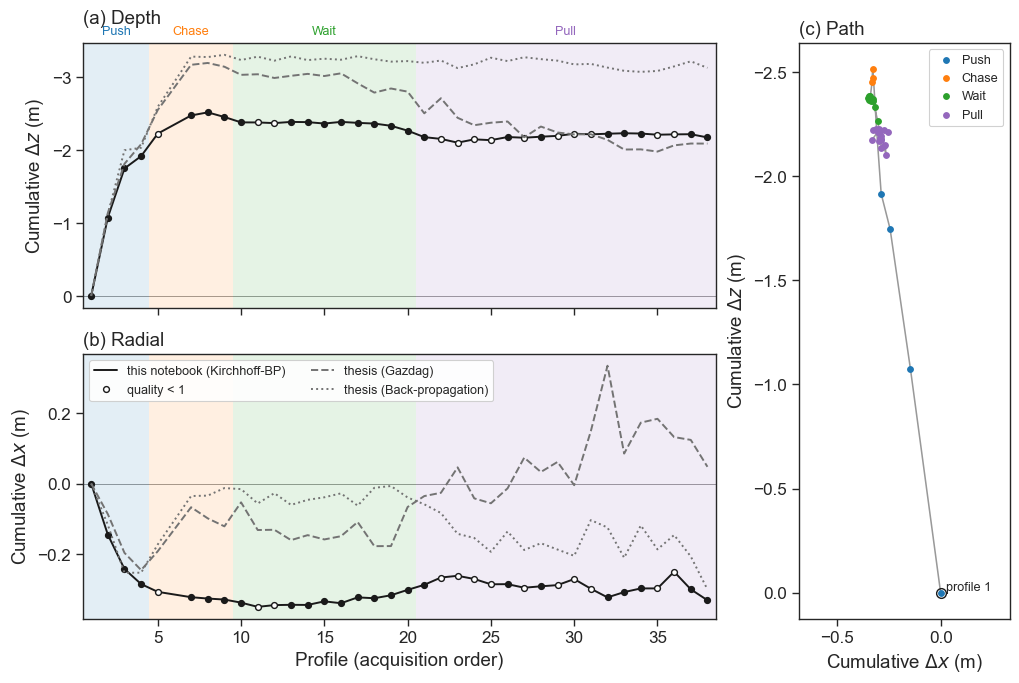

In [9]:
QUALITY_MIN = 1.0      # pairs below this quality are drawn hollow
STAGE_COLORS = dict(Push='tab:blue', Chase='tab:orange', Wait='tab:green', Pull='tab:purple')
THESIS_CSV = (REPO_ROOT / 'TimeLapse_Notebooks' / 'fielddata' / 'output' / 'roi_phase'
              / 'fielddata_stage_displacements.csv')

fig = plt.figure(figsize=(7.2 * FIG_SCALE, 4.8 * FIG_SCALE), layout='constrained')
gs = fig.add_gridspec(2, 2, width_ratios=[3, 1])
ax_z = fig.add_subplot(gs[0, 0])
ax_x = fig.add_subplot(gs[1, 0], sharex=ax_z)
ax_p = fig.add_subplot(gs[:, 1])
fs = 6.5 * FIG_SCALE                                     # small-print font size

profiles = np.r_[RUNS[0], track['profile']]              # profile 1 = start (zero displacement)
good = np.r_[True, track['quality'] >= QUALITY_MIN]
thesis = pd.read_csv(THESIS_CSV) if THESIS_CSV.exists() else None
for ax, col, label in [(ax_z, 'dz', r'Cumulative $\Delta z$ (m)'),
                       (ax_x, 'dx', r'Cumulative $\Delta x$ (m)')]:
    for stage, (lo, hi) in STAGES.items():
        ax.axvspan(lo - 0.5, hi + 0.5, color=STAGE_COLORS[stage], alpha=0.12, lw=0)
    y = np.r_[0.0, track[f'cum_{col}']]
    ax.plot(profiles, y, color='k', lw=FIG_SCALE, label='this notebook (Kirchhoff-BP)')
    ax.plot(profiles[good], y[good], 'o', color='k', ms=3 * FIG_SCALE)
    ax.plot(profiles[~good], y[~good], 'o', mfc='white', mec='k', ms=3 * FIG_SCALE,
            label=f'quality < {QUALITY_MIN:g}')
    if thesis is not None:                               # thesis values are already cumulative
        for method, ls in (('gazdag', '--'), ('backprop', ':')):
            ax.plot(profiles, np.r_[0.0, thesis[f'{col}_{method}']], ls=ls, color='0.45',
                    lw=FIG_SCALE, label=f'thesis ({method.replace("backprop", "back-propagation").capitalize()})')
    ax.axhline(0, color='0.6', lw=0.5 * FIG_SCALE, zorder=0)
    ax.set_ylabel(label)
ax_z.invert_yaxis()                                      # deeper downwards
ax_x.set_xlabel('Profile (acquisition order)')
ax_z.tick_params(labelbottom=False)
ax_z.set_xlim(profiles[0] - 0.5, profiles[-1] + 0.5)
for stage, (lo, hi) in STAGES.items():                   # stage names along the top
    ax_z.text(0.5 * (lo + hi), 1.02, stage, transform=ax_z.get_xaxis_transform(), ha='center',
              va='bottom', fontsize=fs, color=STAGE_COLORS[stage])
ax_x.legend(loc='upper left', fontsize=fs, ncol=2, handlelength=1.8, framealpha=0.9)
ax_z.set_title('(a) Depth', loc='left', pad=14)
ax_x.set_title('(b) Radial', loc='left')

# (c) Path of the cumulative displacement in the (radial, depth) plane
cx, cz = np.r_[0.0, track['cum_dx']], np.r_[0.0, track['cum_dz']]
ax_p.plot(cx, cz, color='0.6', lw=0.8 * FIG_SCALE, zorder=1)
stage_of = np.array([track['stage'].iloc[0], *track['stage']])  # profile 1 belongs to Push
for stage, color in STAGE_COLORS.items():
    on = stage_of == stage
    ax_p.scatter(cx[on], cz[on], s=12 * FIG_SCALE, color=color, label=stage, zorder=2)
ax_p.annotate(f'profile {RUNS[0]}', (cx[0], cz[0]), xytext=(4, 2), textcoords='offset points',
              fontsize=fs)
ax_p.plot(cx[0], cz[0], marker='o', mfc='none', mec='k', ms=5 * FIG_SCALE, ls='none')
ax_p.set_aspect('equal', adjustable='datalim')
ax_p.invert_yaxis()
ax_p.set_xlabel(r'Cumulative $\Delta x$ (m)')
ax_p.set_ylabel(r'Cumulative $\Delta z$ (m)')
ax_p.legend(loc='upper right', fontsize=fs, handletextpad=0.2, framealpha=0.9)
ax_p.set_title('(c) Path', loc='left')

fig.savefig(OUT_DIR / 'natural_movement_track.png', dpi=300, bbox_inches='tight')
plt.show()